### 1. Mount Google Drive
Langkah pertama adalah menghubungkan Google Colab dengan Google Drive Anda.

In [ ]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


### 2. Mencari Folder di "Dibagikan kepada Saya" (Shared with me)
Secara default, folder yang dibagikan kepada Anda tidak langsung muncul di bawah `/content/drive/MyDrive`. Anda perlu membuat shortcut folder tersebut ke Drive Anda terlebih dahulu, atau mencarinya langsung di dalam My Drive jika Anda sudah menambahkan shortcut-nya.

Mari kita definisikan fungsi untuk mencari lokasi folder `Dataset_Kulit_Kucing` di dalam Google Drive.

In [ ]:
# Tentukan nama folder dataset Anda
dataset_folder_name = 'Dataset_Kulit_Kucing'

# Fungsi untuk mencari folder di Google Drive
def find_folder(name, path='/content/drive'):
    for root, dirs, files in os.walk(path):
        if name in dirs:
            return os.path.join(root, name)
    return None

dataset_path = find_folder(dataset_folder_name)

if dataset_path:
    print(f"Folder ditemukan di: {dataset_path}")
    print("Isi folder:")
    print(os.listdir(dataset_path))
else:
    print(f"Folder '{dataset_folder_name}' tidak ditemukan.")
    print("Tips: Pastikan Anda telah menambahkan shortcut folder yang dibagikan tersebut ke 'My Drive' Anda agar mudah diakses.")

Folder 'Dataset_Kulit_Kucing' tidak ditemukan.
Tips: Pastikan Anda telah menambahkan shortcut folder yang dibagikan tersebut ke 'My Drive' Anda agar mudah diakses.


In [ ]:
import os

mydrive_path = '/content/drive/MyDrive'
if os.path.exists(mydrive_path):
    print("Daftar file dan folder di My Drive Anda:")
    items = os.listdir(mydrive_path)
    for item in sorted(items):
        print(f"- {item}")
else:
    print("Drive utama tidak ditemukan atau belum ter-mount dengan benar.")

Daftar file dan folder di My Drive Anda:
- Berkas Beasiswa
- Berkas Wisuda
- Colab Notebooks
- Dataset_Kulit_Kucing
- IMG_0718.jpeg
- KUESIONER PENELITIAN PENGARUH MOTIVASI, DISIPLIN, DAN LINGKUNGAN TERHADAP KINERJA MITRA SENSUS EKONOMI (Studi pada Mitra Sensus Ekonomi 2026 Kecamatan Bulik).gform
- Motif Batik
- TrustWalletBackup
- Undangan Pernikahan Siti & Adam.gsite
- agustinaWahyu
- cd5bd7fa-466c-41ba-9fcc-098ccedf9aa9.jpg
- palm-disease-dataset
- palm_disease_finetuned_90.keras
- palm_disease_model.h5


### 3. Memverifikasi Dataset dan Melihat Kelas Penyakit
Sekarang dataset sudah terdeteksi. Mari kita muat jalurnya dan lihat folder kelas/kategori penyakit kulit kucing yang tersedia di dalamnya.

In [ ]:
import os

dataset_path = '/content/drive/MyDrive/Dataset_Kulit_Kucing'

if os.path.exists(dataset_path):
    print(f"Dataset berhasil diakses di: {dataset_path}\n")
    # Menampilkan kelas penyakit (sub-folder)
    categories = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]
    print(f"Ditemukan {len(categories)} kelas penyakit kulit kucing:")
    for cat in sorted(categories):
        num_images = len(os.listdir(os.path.join(dataset_path, cat)))
        print(f"- {cat}: {num_images} gambar")
else:
    print("Folder dataset tidak ditemukan. Pastikan nama folder dan lokasinya sudah sesuai.")

Dataset berhasil diakses di: /content/drive/MyDrive/Dataset_Kulit_Kucing

Ditemukan 3 kelas penyakit kulit kucing:
- test: 5 gambar
- train: 5 gambar
- val: 5 gambar


### 4. Mengetahui Kategori Penyakit Kulit Kucing di dalam Split Data
Mari kita lihat sub-folder atau kelas penyakit yang ada di dalam direktori `train`, `val`, dan `test`.

In [ ]:
import os

dataset_path = '/content/drive/MyDrive/Dataset_Kulit_Kucing'
splits = ['train', 'val', 'test']

for split in splits:
    split_dir = os.path.join(dataset_path, split)
    if os.path.exists(split_dir):
        subfolders = [d for d in os.listdir(split_dir) if os.path.isdir(os.path.join(split_dir, d))]
        print(f"\nStruktur di dalam folder '{split}':")
        for sub in sorted(subfolders):
            sub_path = os.path.join(split_dir, sub)
            num_imgs = len([f for f in os.listdir(sub_path) if os.path.isfile(os.path.join(sub_path, f))])
            print(f"  - {sub}: {num_imgs} gambar")
    else:
        print(f"Folder '{split}' tidak ditemukan di {dataset_path}")


Struktur di dalam folder 'train':
  - dermatitis: 150 gambar
  - flea_allergy: 158 gambar
  - healthy_sehat: 164 gambar
  - ringworm_kurap: 158 gambar
  - scabies_kudis: 164 gambar

Struktur di dalam folder 'val':
  - dermatitis: 34 gambar
  - flea_allergy: 29 gambar
  - healthy_sehat: 36 gambar
  - ringworm_kurap: 37 gambar
  - scabies_kudis: 34 gambar

Struktur di dalam folder 'test':
  - dermatitis: 29 gambar
  - flea_allergy: 40 gambar
  - healthy_sehat: 35 gambar
  - ringworm_kurap: 31 gambar
  - scabies_kudis: 35 gambar


### 5. Menyiapkan Data Generator dan Augmentasi Gambar
Kita akan menggunakan `ImageDataGenerator` untuk melakukan rescaling gambar menjadi `1/255` serta menerapkan teknik augmentasi (seperti rotasi, pergeseran lebar/tinggi, pencerminan horizontal) pada data latih agar model tidak mudah overfitting.

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Definisikan parameter utama
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_dir = '/content/drive/MyDrive/Dataset_Kulit_Kucing/train'
val_dir = '/content/drive/MyDrive/Dataset_Kulit_Kucing/val'
test_dir = '/content/drive/MyDrive/Dataset_Kulit_Kucing/test'

# Data Generator dengan augmentasi untuk Train
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Data Generator tanpa augmentasi untuk Validation & Test (hanya rescaling)
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Setup generator
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# Menyimpan label kelas untuk referensi nanti
class_names = list(train_generator.class_indices.keys())
print("\nMapping Label Kelas:", train_generator.class_indices)

Found 793 images belonging to 5 classes.
Found 170 images belonging to 5 classes.
Found 170 images belonging to 5 classes.

Mapping Label Kelas: {'dermatitis': 0, 'flea_allergy': 1, 'healthy_sehat': 2, 'ringworm_kurap': 3, 'scabies_kudis': 4}


### 6. Membangun Model Transfer Learning (MobileNetV2)
Kami membekukan (freeze) layer dasar dari MobileNetV2 dan menambahkan dense layer baru di bagian atas untuk mengklasifikasikan 5 kategori penyakit kulit kucing.

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam

# Muat model dasar MobileNetV2 tanpa lapisan klasifikasi atas
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Bekukan bobot dari base model
base_model.trainable = False

# Tambahkan arsitektur kustom di atasnya
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)  # Mencegah overfitting
predictions = Dense(5, activation='softmax')(x) # 5 kelas output

# Gabungkan menjadi satu model utuh
model = Model(inputs=base_model.input, outputs=predictions)

# Kompilasi model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 7. Melatih Model (Training)
Kita akan menggunakan callback `EarlyStopping` dan `ModelCheckpoint` agar proses pelatihan otomatis berhenti jika akurasi validasi sudah tidak meningkat, serta mengamankan model terbaik secara otomatis.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Konfigurasi Callbacks
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint('model_kulit_kucing_terbaik.keras', monitor='val_loss', save_best_only=True, verbose=1)
]

# Latih model selama 20 epochs (bisa disesuaikan)
EPOCHS = 20
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.2263 - loss: 1.8603
Epoch 1: val_loss improved from None to 1.49952, saving model to model_kulit_kucing_terbaik.keras

Epoch 1: finished saving model to model_kulit_kucing_terbaik.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 298s 12s/step - accuracy: 0.2573 - loss: 1.7573 - val_accuracy: 0.4471 - val_loss: 1.4995
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3975 - loss: 1.4695
Epoch 2: val_loss improved from 1.49952 to 1.28581, saving model to model_kulit_kucing_terbaik.keras

Epoch 2: finished saving model to model_kulit_kucing_terbaik.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 73s 3s/step - accuracy: 0.4224 - loss: 1.4114 - val_accuracy: 0.5412 - val_loss: 1.2858
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4575 - loss: 1.3019
Epoch 3: val_loss improved from 1.28581 to 1.16632, saving model to model_kulit_kucing_terbaik.keras

Epoch 3: finished saving model to model_kulit_kucing_terbaik.keras
25/25 ━━━━━━━━━

### 8. Visualisasi Riwayat Pelatihan (Loss & Accuracy)
Mari kita tampilkan grafik performa model selama proses pelatihan untuk menganalisis apakah terjadi overfitting atau underfitting.

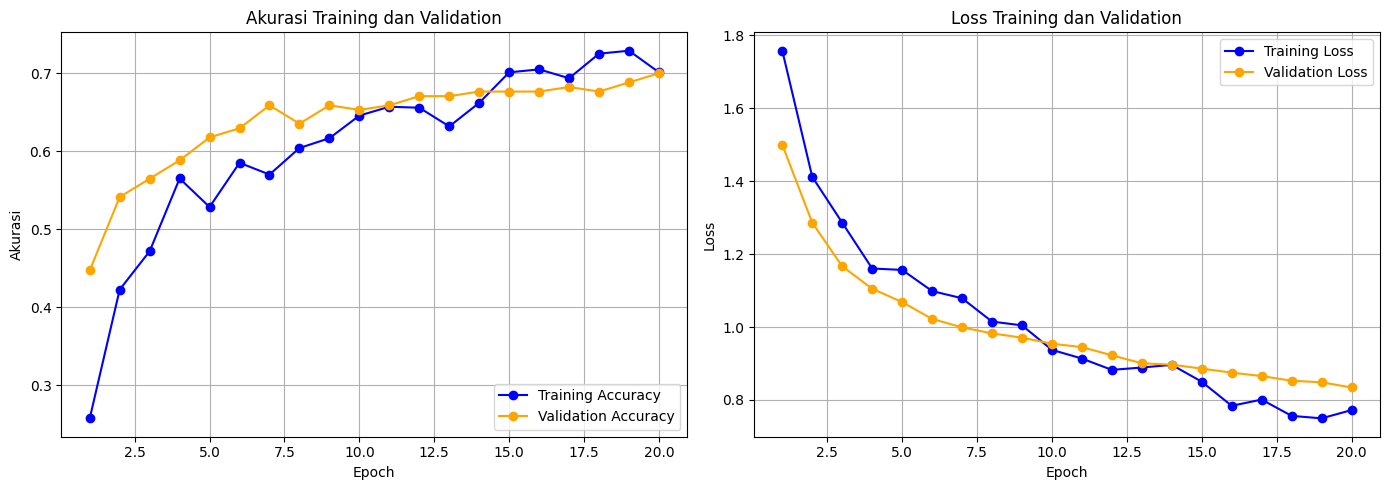

In [ ]:
import matplotlib.pyplot as plt

# Ambil data akurasi dan loss
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# Visualisasi
plt.figure(figsize=(14, 5))

# Grafik Akurasi
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='blue', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange', marker='o')
plt.title('Akurasi Training dan Validation')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend(loc='lower right')
plt.grid(True)

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='blue', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange', marker='o')
plt.title('Loss Training dan Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

### 9. Evaluasi Model pada Data Uji (Test Dataset)
Kita akan menguji performa model menggunakan data di direktori `test`, membuat laporan klasifikasi (precision, recall, f1-score), dan menampilkan Confusion Matrix.

Akurasi Model pada Data Uji: 73.53%
Loss Model pada Data Uji: 0.8021

6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step
Laporan Klasifikasi (Classification Report):
                precision    recall  f1-score   support

    dermatitis       0.55      0.38      0.45        29
  flea_allergy       0.81      0.85      0.83        40
 healthy_sehat       0.77      0.97      0.86        35
ringworm_kurap       0.60      0.68      0.64        31
 scabies_kudis       0.86      0.71      0.78        35

      accuracy                           0.74       170
     macro avg       0.72      0.72      0.71       170
  weighted avg       0.73      0.74      0.73       170



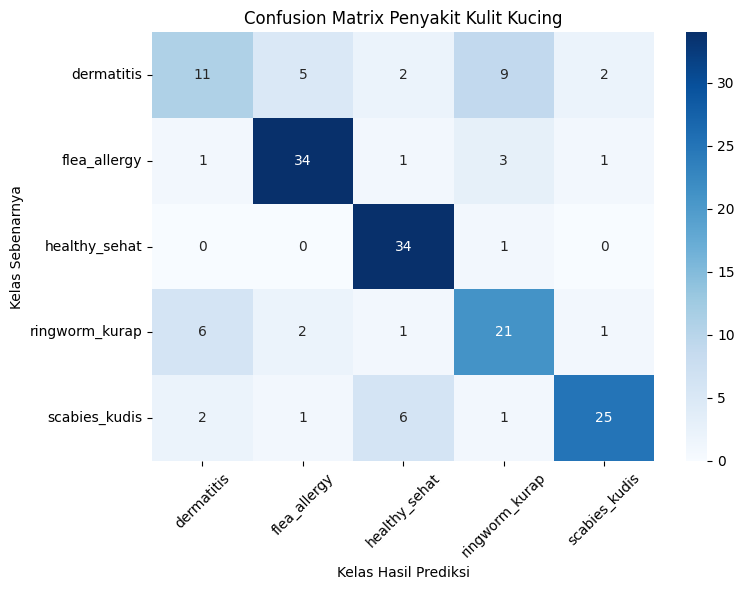

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Evaluasi performa loss & akurasi secara keseluruhan
test_loss, test_acc = model.evaluate(test_generator, verbose=0)
print(f"Akurasi Model pada Data Uji: {test_acc * 100:.2f}%")
print(f"Loss Model pada Data Uji: {test_loss:.4f}\n")

# Prediksi data uji
test_generator.reset()
Y_pred = model.predict(test_generator)
y_pred = np.argmax(Y_pred, axis=1)
y_true = test_generator.classes

# Tampilkan Laporan Klasifikasi
print("Laporan Klasifikasi (Classification Report):")
print(classification_report(y_true, y_pred, target_names=class_names))

# Tampilkan Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix Penyakit Kulit Kucing')
plt.ylabel('Kelas Sebenarnya')
plt.xlabel('Kelas Hasil Prediksi')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 10. Menguji Model dengan Gambar Baru (Interaktif)
Jalankan cell di bawah ini untuk mengunggah gambar kucing baru dari komputer Anda dan melihat hasil klasifikasi penyakitnya.

In [ ]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model

# Load model terbaik yang telah disimpan
best_model = load_model('model_kulit_kucing_terbaik.keras')

# Definisikan daftar nama kelas sesuai dengan training
class_names = ['dermatitis', 'flea_allergy', 'healthy_sehat', 'ringworm_kurap', 'scabies_kudis']

# Unggah file gambar
uploaded = files.upload()

for fn in uploaded.keys():
    # Load gambar dan sesuaikan ukurannya
    img_path = fn
    img = image.load_img(img_path, target_size=(224, 224))

    # Konversi gambar ke array dan lakukan scaling
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array /= 255.0

    # Lakukan prediksi
    predictions = best_model.predict(img_array)
    score = predictions[0]
    predicted_class_idx = np.argmax(score)
    predicted_class = class_names[predicted_class_idx]
    confidence = score[predicted_class_idx] * 100

    # Tampilkan Gambar dan Hasil
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Prediksi: {predicted_class} ({confidence:.2f}%)")
    plt.show()

    print(f"Detail Probabilitas:")
    for name, conf in zip(class_names, score):
        print(f"- {name}: {conf * 100:.2f}%")

KeyboardInterrupt: 

In [ ]:
import os
import random
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model

# 1. Muat kembali model terbaik
best_model = load_model('model_kulit_kucing_terbaik.keras')

# 2. Definisikan jalur dataset dan kelas
test_dir = '/content/drive/MyDrive/Dataset_Kulit_Kucing/test'
class_names = ['dermatitis', 'flea_allergy', 'healthy_sehat', 'ringworm_kurap', 'scabies_kudis']

# 3. Kumpulkan 50 gambar (10 gambar secara acak dari setiap kelas)
selected_images = []
for class_name in class_names:
    class_path = os.path.join(test_dir, class_name)
    all_images = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    # Ambil 10 gambar secara acak (atau semua jika gambar di folder kurang dari 10)
    sampled = random.sample(all_images, min(10, len(all_images)))
    for img_name in sampled:
        selected_images.append({
            'path': os.path.join(class_path, img_name),
            'actual_class': class_name,
            'filename': img_name
        })

# Jika total gambar tidak pas 50 karena keterbatasan data, kita infokan
print(f"Total gambar yang dipilih untuk pengujian: {len(selected_images)}\n")

# 4. Lakukan evaluasi prediksi satu per satu
correct_predictions = 0

print(f"{'No':<3} | {'Nama File':<35} | {'Kelas Asli':<15} | {'Prediksi Model':<15} | {'Hasil':<8} | {'Confidence':<10}")
print("-" * 98)

for idx, item in enumerate(selected_images, 1):
    # Load & preprocess gambar
    img = image.load_img(item['path'], target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array /= 255.0

    # Prediksi
    predictions = best_model.predict(img_array, verbose=0)
    score = predictions[0]
    predicted_class_idx = np.argmax(score)
    predicted_class = class_names[predicted_class_idx]
    confidence = score[predicted_class_idx] * 100

    # Tentukan Benar / Salah
    is_correct = (predicted_class == item['actual_class'])
    status = "BENAR" if is_correct else "SALAH"

    if is_correct:
        correct_predictions += 1

    print(f"{idx:<3} | {item['filename'][:33]:<35} | {item['actual_class']:<15} | {predicted_class:<15} | {status:<8} | {confidence:.2f}%")

# 5. Hitung & Tampilkan Akurasi
total_tested = len(selected_images)
final_accuracy = (correct_predictions / total_tested) * 100
print("\n" + "="*40)
print(f"Hasil Akhir Pengujian:")
print(f"- Total Gambar Diuji : {total_tested}")
print(f"- Prediksi Benar     : {correct_predictions}")
print(f"- Prediksi Salah     : {total_tested - correct_predictions}")
print(f"- Akurasi Pengujian  : {final_accuracy:.2f}%")
print("="*40)

Total gambar yang dipilih untuk pengujian: 50

No  | Nama File                           | Kelas Asli      | Prediksi Model  | Hasil    | Confidence
--------------------------------------------------------------------------------------------------
1   | cat skin_Dermatitis 072.jpg         | dermatitis      | healthy_sehat   | SALAH    | 97.60%
2   | cat skin_Dermatitis 155.jpg         | dermatitis      | ringworm_kurap  | SALAH    | 40.48%
3   | cat skin_Dermatitis 061.jpg         | dermatitis      | dermatitis      | BENAR    | 47.92%
4   | cat skin_Dermatitis 147.jpg         | dermatitis      | healthy_sehat   | SALAH    | 56.96%
5   | cat skin_Dermatitis 016.jpg         | dermatitis      | ringworm_kurap  | SALAH    | 59.47%
6   | cat skin_Dermatitis 006.jpg         | dermatitis      | ringworm_kurap  | SALAH    | 80.92%
7   | cat skin_Dermatitis 102.jpg         | dermatitis      | flea_allergy    | SALAH    | 29.08%
8   | cat skin_Dermatitis 158.jpg         | dermatitis      | derm

### 11. Melakukan Fine-Tuning pada Model
Kita akan membuka sebagian layer teratas dari MobileNetV2 dan melatih ulang dengan learning rate yang sangat rendah untuk mengoptimalkan akurasi klasifikasi.

In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# 1. Buka kembali base model agar bisa dituning
base_model.trainable = True

# Letakkan batas: Kita hanya unfreeze layer dari indeks 100 ke atas
fine_tune_at = 100

# Bekukan semua layer sebelum layer ke-100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# 2. Kompilasi ulang model dengan Learning Rate yang sangat kecil
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 2,026,053 (7.73 MB)

 Non-trainable params: 396,544 (1.51 MB)

In [ ]:
# 3. Definisikan callback baru untuk menyimpan model fine-tuned terbaik
callbacks_finetune = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint('model_kulit_kucing_finetuned.keras', monitor='val_loss', save_best_only=True, verbose=1)
]

# 4. Latih kembali model (Fine-tuning)
fine_tune_epochs = 15
total_epochs = len(history.epoch) + fine_tune_epochs

history_fine = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=total_epochs,
    initial_epoch=history.epoch[-1] + 1,
    callbacks=callbacks_finetune
)

Epoch 21/35
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.5022 - loss: 1.3221
Epoch 21: val_loss improved from None to 0.83427, saving model to model_kulit_kucing_finetuned.keras

Epoch 21: finished saving model to model_kulit_kucing_finetuned.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 146s 5s/step - accuracy: 0.5284 - loss: 1.2450 - val_accuracy: 0.6941 - val_loss: 0.8343
Epoch 22/35
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5699 - loss: 1.0827
Epoch 22: val_loss did not improve from 0.83427
25/25 ━━━━━━━━━━━━━━━━━━━━ 114s 5s/step - accuracy: 0.5939 - loss: 1.0666 - val_accuracy: 0.6471 - val_loss: 0.8601
Epoch 23/35
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5973 - loss: 1.0677
Epoch 23: val_loss did not improve from 0.83427
25/25 ━━━━━━━━━━━━━━━━━━━━ 111s 5s/step - accuracy: 0.6179 - loss: 1.0061 - val_accuracy: 0.6294 - val_loss: 0.8880
Epoch 24/35
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6370 - loss: 0.9460
Epoch 24: val_loss did not improve from 0.83427


In [ ]:
# 5. Evaluasi kembali model yang telah di-fine-tune pada data uji
test_loss, test_acc = model.evaluate(test_generator, verbose=0)
print(f"Akurasi Baru setelah Fine-Tuning pada Data Uji: {test_acc * 100:.2f}%")
print(f"Loss Baru setelah Fine-Tuning pada Data Uji: {test_loss:.4f}")

Akurasi Baru setelah Fine-Tuning pada Data Uji: 72.35%
Loss Baru setelah Fine-Tuning pada Data Uji: 0.8111


### 12. Strategi Tingkat Lanjut: Arsitektur Kokoh + Penurunan Learning Rate Dinamis
Kita membuat model baru dengan basis MobileNetV2, namun menambahkan lapisan Batch Normalization, Dropout yang disesuaikan, serta callback `ReduceLROnPlateau` agar proses optimasi berjalan jauh lebih presisi dan stabil.

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model

# 1. Re-build Base Model
base_model_advanced = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Izinkan training hanya pada 30 layer terakhir
base_model_advanced.trainable = True
fine_tune_at = len(base_model_advanced.layers) - 30
for layer in base_model_advanced.layers[:fine_tune_at]:
    layer.trainable = False

# 2. Arsitektur Tambahan yang Lebih Stabil
x = base_model_advanced.output
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.4)(x)
predictions = tf.keras.layers.Dense(5, activation='softmax')(x)

model_advanced = Model(inputs=base_model_advanced.input, outputs=predictions)

# Compiling dengan Learning Rate awal sedang-kecil
model_advanced.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# 3. Setup Callbacks yang Dinamis
callbacks_advanced = [
    EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1),
    ModelCheckpoint('model_kulit_kucing_advanced.keras', monitor='val_loss', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1)
]

# 4. Latih Model Baru
history_advanced = model_advanced.fit(
    train_generator,
    validation_data=val_generator,
    epochs=25,
    callbacks=callbacks_advanced
)

Epoch 1/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.2823 - loss: 2.7060
Epoch 1: val_loss improved from None to 1.98742, saving model to model_kulit_kucing_advanced.keras

Epoch 1: finished saving model to model_kulit_kucing_advanced.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 108s 4s/step - accuracy: 0.3733 - loss: 2.3945 - val_accuracy: 0.4000 - val_loss: 1.9874 - learning_rate: 1.0000e-04
Epoch 2/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6071 - loss: 1.6417
Epoch 2: val_loss improved from 1.98742 to 1.68121, saving model to model_kulit_kucing_advanced.keras

Epoch 2: finished saving model to model_kulit_kucing_advanced.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 94s 4s/step - accuracy: 0.6141 - loss: 1.6020 - val_accuracy: 0.4824 - val_loss: 1.6812 - learning_rate: 1.0000e-04
Epoch 3/25
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6879 - loss: 1.3537
Epoch 3: val_loss improved from 1.68121 to 1.63671, saving model to model_kulit_kucing_advanced.keras

Epoch 3: finished savi

In [ ]:
# 5. Evaluasi Hasil Akhir Model Advanced pada Data Test
test_loss_adv, test_acc_advanced = model_advanced.evaluate(test_generator, verbose=0)
print(f"Akurasi Model Advanced Baru pada Data Uji: {test_acc_advanced * 100:.2f}%")
print(f"Loss Model Advanced Baru pada Data Uji: {test_loss_adv:.4f}")

Akurasi Model Advanced Baru pada Data Uji: 57.06%
Loss Model Advanced Baru pada Data Uji: 1.5220


### 13. Fine-Tuning Terukur pada Model Terbaik (73.53%)
Kita akan memuat kembali model penyelamat kita yang paling akurat, membuka hanya 15 layer terakhir dari MobileNetV2 bawaannya, lalu melatihnya kembali dengan learning rate ultra-rendah (`1e-6`).

In [ ]:
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# 1. Muat kembali model terbaik asli kita (73.53%)
model_fine_safe = load_model('model_kulit_kucing_terbaik.keras')

# 2. Cari base model MobileNetV2 di dalam model tersebut
# Model kita tersusun dari: base_model -> GlobalAveragePooling2D -> Dense -> Dropout -> Dense
# Mari kita temukan layer MobileNetV2 dan unfreeze 15 layer teratasnya saja
for layer in model_fine_safe.layers:
    if layer.name == 'mobilenetv2_1.00_224' or isinstance(layer, tf.keras.Model):
        layer.trainable = True
        # Bekukan semua layer kecuali 15 layer terakhir dari MobileNetV2
        fine_tune_at = len(layer.layers) - 15
        for sub_layer in layer.layers[:fine_tune_at]:
            sub_layer.trainable = False
        for sub_layer in layer.layers[fine_tune_at:]:
            sub_layer.trainable = True

# 3. Kompilasi ulang dengan learning rate ultra-rendah
model_fine_safe.compile(
    optimizer=Adam(learning_rate=1e-6),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_fine_safe.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# 4. Callback khusus untuk fine-tuning aman
callbacks_safe = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1),
    ModelCheckpoint('model_kulit_kucing_v2_final.keras', monitor='val_loss', save_best_only=True, verbose=1)
]

# 5. Jalankan training tambahan selama 10 epoch
history_safe = model_fine_safe.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=callbacks_safe
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7020 - loss: 0.8035
Epoch 1: val_loss improved from None to 0.83378, saving model to model_kulit_kucing_v2_final.keras

Epoch 1: finished saving model to model_kulit_kucing_v2_final.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 83s 3s/step - accuracy: 0.6986 - loss: 0.7818 - val_accuracy: 0.7000 - val_loss: 0.8338
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7228 - loss: 0.7517
Epoch 2: val_loss improved from 0.83378 to 0.83356, saving model to model_kulit_kucing_v2_final.keras

Epoch 2: finished saving model to model_kulit_kucing_v2_final.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 71s 3s/step - accuracy: 0.7377 - loss: 0.7403 - val_accuracy: 0.7000 - val_loss: 0.8336
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7454 - loss: 0.7125
Epoch 3: val_loss improved from 0.83356 to 0.83339, saving model to model_kulit_kucing_v2_final.keras

Epoch 3: finished saving model to model_kulit_kucing_v2_final.keras
25/25 ━━━━━

In [ ]:
# 6. Evaluasi performa model final hasil fine-tuning aman pada data uji
test_loss_safe, test_acc_safe = model_fine_safe.evaluate(test_generator, verbose=0)
print(f"Akurasi Model setelah Safe Fine-Tuning: {test_acc_safe * 100:.2f}%")
print(f"Loss Model setelah Safe Fine-Tuning: {test_loss_safe:.4f}")

Akurasi Model setelah Safe Fine-Tuning: 75.88%
Loss Model setelah Safe Fine-Tuning: 0.8008


In [ ]:
import os
import random
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model

# 1. Muat kembali model final hasil safe fine-tuning terbaik kita
final_model = load_model('model_kulit_kucing_v2_final.keras')

# 2. Definisikan jalur dataset dan kelas
test_dir = '/content/drive/MyDrive/Dataset_Kulit_Kucing/test'
class_names = ['dermatitis', 'flea_allergy', 'healthy_sehat', 'ringworm_kurap', 'scabies_kudis']

# 3. Kumpulkan 50 gambar secara acak (10 gambar dari setiap kelas)
selected_images = []
for class_name in class_names:
    class_path = os.path.join(test_dir, class_name)
    all_images = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    sampled = random.sample(all_images, min(10, len(all_images)))
    for img_name in sampled:
        selected_images.append({
            'path': os.path.join(class_path, img_name),
            'actual_class': class_name,
            'filename': img_name
        })

print(f"Total gambar yang dipilih untuk pengujian ulang: {len(selected_images)}\n")

# 4. Lakukan evaluasi prediksi satu per satu
correct_predictions = 0

print(f"{'No':<3} | {'Nama File':<35} | {'Kelas Asli':<15} | {'Prediksi Model':<15} | {'Hasil':<8} | {'Confidence':<10}")
print("-" * 98)

for idx, item in enumerate(selected_images, 1):
    img = image.load_img(item['path'], target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array /= 255.0

    predictions = final_model.predict(img_array, verbose=0)
    score = predictions[0]
    predicted_class_idx = np.argmax(score)
    predicted_class = class_names[predicted_class_idx]
    confidence = score[predicted_class_idx] * 100

    is_correct = (predicted_class == item['actual_class'])
    status = "BENAR" if is_correct else "SALAH"

    if is_correct:
        correct_predictions += 1

    print(f"{idx:<3} | {item['filename'][:33]:<35} | {item['actual_class']:<15} | {predicted_class:<15} | {status:<8} | {confidence:.2f}%")

# 5. Hitung & Tampilkan Akurasi
total_tested = len(selected_images)
final_accuracy = (correct_predictions / total_tested) * 100
print("\n" + "="*40)
print(f"Hasil Pengujian Model Final:")
print(f"- Total Gambar Diuji : {total_tested}")
print(f"- Prediksi Benar     : {correct_predictions}")
print(f"- Prediksi Salah     : {total_tested - correct_predictions}")
print(f"- Akurasi Pengujian  : {final_accuracy:.2f}%")
print("="*40)

Total gambar yang dipilih untuk pengujian ulang: 50

No  | Nama File                           | Kelas Asli      | Prediksi Model  | Hasil    | Confidence
--------------------------------------------------------------------------------------------------
1   | cat skin_Dermatitis 203.jpg         | dermatitis      | dermatitis      | BENAR    | 84.03%
2   | cat skin_Dermatitis 164.jpg         | dermatitis      | ringworm_kurap  | SALAH    | 50.65%
3   | cat skin_Dermatitis 072.jpg         | dermatitis      | healthy_sehat   | SALAH    | 97.68%
4   | cat skin_Dermatitis 212.jpg         | dermatitis      | flea_allergy    | SALAH    | 47.85%
5   | cat skin_Dermatitis 155.jpg         | dermatitis      | ringworm_kurap  | SALAH    | 38.02%
6   | cat skin_Dermatitis 218.jpg         | dermatitis      | ringworm_kurap  | SALAH    | 46.03%
7   | cat skin_Dermatitis 131.jpg         | dermatitis      | dermatitis      | BENAR    | 80.36%
8   | cat skin_Dermatitis 213.jpg         | dermatitis      

In [ ]:
# Uji ulang 50 gambar dengan format ringkasan agar tidak terpotong oleh Colab
correct_predictions = 0
class_correct = {c: 0 for c in class_names}
class_total = {c: 0 for c in class_names}

for idx, item in enumerate(selected_images, 1):
    img = image.load_img(item['path'], target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array /= 255.0

    predictions = final_model.predict(img_array, verbose=0)
    predicted_class = class_names[np.argmax(predictions[0])]
    actual_class = item['actual_class']

    class_total[actual_class] += 1
    if predicted_class == actual_class:
        correct_predictions += 1
        class_correct[actual_class] += 1

print("=== RINGKASAN EVALUASI 50 GAMBAR ACAK ===\n")
for c in class_names:
    acc = (class_correct[c] / class_total[c]) * 100 if class_total[c] > 0 else 0
    print(f"Kelas {c:<15}: {class_correct[c]}/{class_total[c]} Benar ({acc:.2f}%)")

total_tested = len(selected_images)
final_accuracy = (correct_predictions / total_tested) * 100
print("\n" + "="*40)
print(f"AKURASI KESELURUHAN: {final_accuracy:.2f}%")
print(f"Prediksi Benar: {correct_predictions} | Salah: {total_tested - correct_predictions}")
print("="*40)

=== RINGKASAN EVALUASI 50 GAMBAR ACAK ===

Kelas dermatitis     : 3/10 Benar (30.00%)
Kelas flea_allergy   : 7/10 Benar (70.00%)
Kelas healthy_sehat  : 10/10 Benar (100.00%)
Kelas ringworm_kurap : 6/10 Benar (60.00%)
Kelas scabies_kudis  : 7/10 Benar (70.00%)

AKURASI KESELURUHAN: 66.00%
Prediksi Benar: 33 | Salah: 17


In [ ]:
import os
import random
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model

# 1. Muat kembali model final hasil safe fine-tuning terbaik kita
final_model = load_model('model_kulit_kucing_v2_final.keras')

# 2. Definisikan jalur dataset dan kelas
test_dir = '/content/drive/MyDrive/Dataset_Kulit_Kucing/test'
class_names = ['dermatitis', 'flea_allergy', 'healthy_sehat', 'ringworm_kurap', 'scabies_kudis']

# 3. Kumpulkan 100 gambar secara acak (20 gambar dari setiap kelas)
selected_images_100 = []
for class_name in class_names:
    class_path = os.path.join(test_dir, class_name)
    all_images = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    # Mengambil hingga 20 gambar acak per kelas
    sampled = random.sample(all_images, min(20, len(all_images)))
    for img_name in sampled:
        selected_images_100.append({
            'path': os.path.join(class_path, img_name),
            'actual_class': class_name,
            'filename': img_name
        })

print(f"Total gambar yang dipilih untuk pengujian baru: {len(selected_images_100)}\n")

# 4. Lakukan evaluasi prediksi satu per satu
correct_predictions = 0
class_correct = {c: 0 for c in class_names}
class_total = {c: 0 for c in class_names}

for idx, item in enumerate(selected_images_100, 1):
    img = image.load_img(item['path'], target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array /= 255.0

    predictions = final_model.predict(img_array, verbose=0)
    predicted_class = class_names[np.argmax(predictions[0])]
    actual_class = item['actual_class']

    class_total[actual_class] += 1
    if predicted_class == actual_class:
        correct_predictions += 1
        class_correct[actual_class] += 1

# 5. Tampilkan Ringkasan Evaluasi
print("=== RINGKASAN EVALUASI 100 GAMBAR ACAK ===\n")
for c in class_names:
    acc = (class_correct[c] / class_total[c]) * 100 if class_total[c] > 0 else 0
    print(f"Kelas {c:<15}: {class_correct[c]}/{class_total[c]} Benar ({acc:.2f}%)")

total_tested = len(selected_images_100)
final_accuracy = (correct_predictions / total_tested) * 100
print("\n" + "="*40)
print(f"AKURASI KESELURUHAN: {final_accuracy:.2f}%")
print(f"Prediksi Benar: {correct_predictions} | Salah: {total_tested - correct_predictions}")
print("="*40)

Total gambar yang dipilih untuk pengujian baru: 100

=== RINGKASAN EVALUASI 100 GAMBAR ACAK ===

Kelas dermatitis     : 8/20 Benar (40.00%)
Kelas flea_allergy   : 16/20 Benar (80.00%)
Kelas healthy_sehat  : 20/20 Benar (100.00%)
Kelas ringworm_kurap : 15/20 Benar (75.00%)
Kelas scabies_kudis  : 14/20 Benar (70.00%)

AKURASI KESELURUHAN: 73.00%
Prediksi Benar: 73 | Salah: 27


Memproses ulang gambar untuk menghasilkan Confusion Matrix...


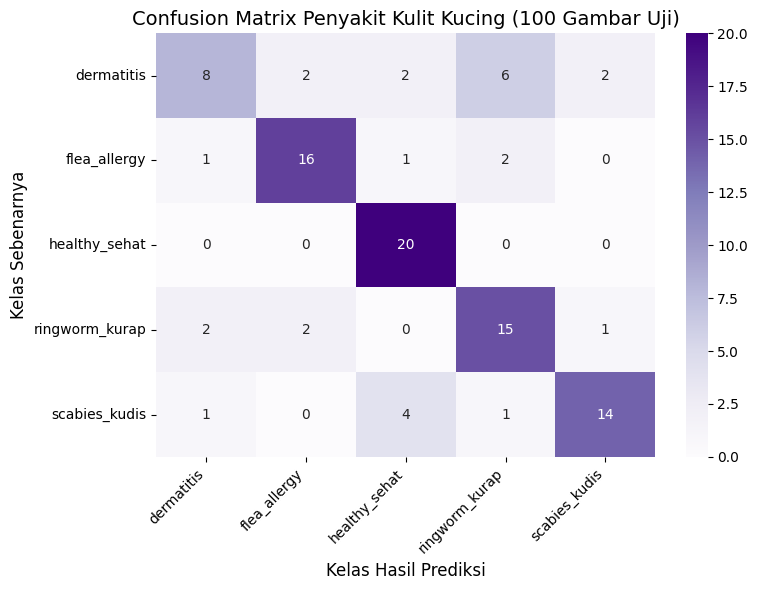

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np
from tensorflow.keras.preprocessing import image

# 1. Kumpulkan prediksi asli (y_true) dan prediksi model (y_pred) dari 100 gambar
y_true_100 = []
y_pred_100 = []

print("Memproses ulang gambar untuk menghasilkan Confusion Matrix...")
for item in selected_images_100:
    # Load & Preprocess
    img = image.load_img(item['path'], target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array /= 255.0

    # Prediksi
    predictions = final_model.predict(img_array, verbose=0)
    predicted_class_idx = np.argmax(predictions[0])

    # Ambil indeks kelas asli dan kelas prediksi
    actual_class_idx = class_names.index(item['actual_class'])

    y_true_100.append(actual_class_idx)
    y_pred_100.append(predicted_class_idx)

# 2. Hitung Confusion Matrix
cm_100 = confusion_matrix(y_true_100, y_pred_100)

# 3. Visualisasikan Confusion Matrix dengan Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_100,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix Penyakit Kulit Kucing (100 Gambar Uji)', fontsize=14)
plt.ylabel('Kelas Sebenarnya', fontsize=12)
plt.xlabel('Kelas Hasil Prediksi', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files

# Mengunduh file model terbaik v2 final
model_path = 'model_kulit_kucing_v2_final.keras'
try:
    files.download(model_path)
    print("Proses unduhan dimulai...")
except Exception as e:
    print(f"Gagal mengunduh: {e}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Proses unduhan dimulai...
